Phiên bản sử dụng: Anaconda3-2024.10-1-Windows-x86_64

Dữ liệu lấy từ: https://www.kaggle.com/datasets/thedevastator/uncover-global-trends-in-mental-health-disorder/data

# 1. Thu nhập và tải dữ liệu

In [1]:
#Khai báo thư viện
import numpy as np
import pandas as pd

#đọc dữ liệu
df=pd.read_csv("health.csv", index_col='index',low_memory=False)
df.info()
df

<class 'pandas.core.frame.DataFrame'>
Index: 108553 entries, 0 to 108552
Data columns (total 10 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Entity                     108328 non-null  object 
 1   Code                       103140 non-null  object 
 2   Year                       108328 non-null  object 
 3   Schizophrenia (%)          25650 non-null   object 
 4   Bipolar disorder (%)       19237 non-null   object 
 5   Eating disorders (%)       100179 non-null  object 
 6   Anxiety disorders (%)      6412 non-null    float64
 7   Drug use disorders (%)     6412 non-null    float64
 8   Depression (%)             6412 non-null    float64
 9   Alcohol use disorders (%)  6412 non-null    float64
dtypes: float64(4), object(6)
memory usage: 9.1+ MB


,Entity,Code,Year,Schizophrenia (%),Bipolar disorder (%),Eating disorders (%),Anxiety disorders (%),Drug use disorders (%),Depression (%),Alcohol use disorders (%)
index,,,,,,,,,,
0,Afghanistan,AFG,1990,0.16056,0.697779,0.101855,4.828830,1.677082,4.071831,0.672404
1,Afghanistan,AFG,1991,0.160312,0.697961,0.099313,4.829740,1.684746,4.079531,0.671768
2,Afghanistan,AFG,1992,0.160135,0.698107,0.096692,4.831108,1.694334,4.088358,0.670644
3,Afghanistan,AFG,1993,0.160037,0.698257,0.094336,4.830864,1.705320,4.096190,0.669738
4,Afghanistan,AFG,1994,0.160022,0.698469,0.092439,4.829423,1.716069,4.099582,0.669260
...,...,...,...,...,...,...,...,...,...,...
108548,Zimbabwe,ZWE,2013,303564.60359,NaN,NaN,NaN,NaN,NaN,NaN
108549,Zimbabwe,ZWE,2014,311665.769283,NaN,NaN,NaN,NaN,NaN,NaN
108550,Zimbabwe,ZWE,2015,320638.507158,NaN,NaN,NaN,NaN,NaN,NaN


* Schizophrenia: Tâm thần phân liệt
* Bipolar disorder: Rối loạn lưỡng cực 
* Eating disorders: Rối loạn ăn uống 
* Anxiety disorders: Rối loạn lo âu 
* Drug use disorders: Rối loạn sử dụng ma túy 
* Depression: Trầm cảm 
* Alcohol use disorders: Rối loạn sử dụng rượu

# 2. Tiền xử lý và làm sạch dữ liệu

In [2]:
# Chuẩn hóa tên cột
df.columns = df.columns.str.strip()

# Kiểm tra lại cột có đúng tên không
print(df.columns.tolist())

['Entity', 'Code', 'Year', 'Schizophrenia (%)', 'Bipolar disorder (%)', 'Eating disorders (%)', 'Anxiety disorders (%)', 'Drug use disorders (%)', 'Depression (%)', 'Alcohol use disorders (%)']


##### Chuyển đổi dữ liệu về đúng định dạng

- Schizophrenia (%),Bipolar disorder (%),Eating disorders (%) → được chuyển thành float64.
- '...' → không thể chuyển đổi dữ liệu nên bị chuyển thành NaN.
- Tham số errors='coerce' trong hàm pd.to_numeric() có vai trò xử lý các giá trị không hợp lệ khi chuyển đổi dữ liệu về kiểu số.

In [3]:
#Chuyển đổi kiểu dữ liệu
df["Schizophrenia (%)"]=pd.to_numeric(df["Schizophrenia (%)"], errors='coerce')
df["Bipolar disorder (%)"]=pd.to_numeric(df["Bipolar disorder (%)"], errors='coerce')
df["Eating disorders (%)"]=pd.to_numeric(df["Eating disorders (%)"], errors='coerce')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 108553 entries, 0 to 108552
Data columns (total 10 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Entity                     108328 non-null  object 
 1   Code                       103140 non-null  object 
 2   Year                       108328 non-null  object 
 3   Schizophrenia (%)          25648 non-null   float64
 4   Bipolar disorder (%)       19236 non-null   float64
 5   Eating disorders (%)       100178 non-null  float64
 6   Anxiety disorders (%)      6412 non-null    float64
 7   Drug use disorders (%)     6412 non-null    float64
 8   Depression (%)             6412 non-null    float64
 9   Alcohol use disorders (%)  6412 non-null    float64
dtypes: float64(7), object(3)
memory usage: 9.1+ MB


,Entity,Code,Year,Schizophrenia (%),Bipolar disorder (%),Eating disorders (%),Anxiety disorders (%),Drug use disorders (%),Depression (%),Alcohol use disorders (%)
index,,,,,,,,,,
0,Afghanistan,AFG,1990,0.160560,0.697779,0.101855,4.828830,1.677082,4.071831,0.672404
1,Afghanistan,AFG,1991,0.160312,0.697961,0.099313,4.829740,1.684746,4.079531,0.671768
2,Afghanistan,AFG,1992,0.160135,0.698107,0.096692,4.831108,1.694334,4.088358,0.670644
3,Afghanistan,AFG,1993,0.160037,0.698257,0.094336,4.830864,1.705320,4.096190,0.669738
4,Afghanistan,AFG,1994,0.160022,0.698469,0.092439,4.829423,1.716069,4.099582,0.669260


In [4]:
#Kiểm tra các giá trị bị thiếu
df.isnull().sum()

Entity                          225
Code                           5413
Year                            225
Schizophrenia (%)             82905
Bipolar disorder (%)          89317
Eating disorders (%)           8375
Anxiety disorders (%)        102141
Drug use disorders (%)       102141
Depression (%)               102141
Alcohol use disorders (%)    102141
dtype: int64

In [5]:
#Tổng số dữ liệu trùng lặp
df.duplicated().sum()

41564

In [6]:
duplicated_data = df[df.duplicated(keep='first')==True]
duplicated_data.count()


Entity                       41340
Code                         40594
Year                         41340
Schizophrenia (%)                0
Bipolar disorder (%)             0
Eating disorders (%)         41339
Anxiety disorders (%)            0
Drug use disorders (%)           0
Depression (%)                   0
Alcohol use disorders (%)        0
dtype: int64

In [7]:
#Loại bỏ các hàng trùng lặp và kiểm tra giá trị null:
df.drop_duplicates(keep='first', inplace=True)
df[df.isna().any(axis=1)==True] 


,Entity,Code,Year,Schizophrenia (%),Bipolar disorder (%),Eating disorders (%),Anxiety disorders (%),Drug use disorders (%),Depression (%),Alcohol use disorders (%)
index,,,,,,,,,,
112,Andean Latin America,NaN,1990,0.195471,0.870564,0.287820,4.217677,0.608921,2.621781,1.748912
113,Andean Latin America,NaN,1991,0.195484,0.870876,0.289362,4.220261,0.610489,2.631717,1.743910
114,Andean Latin America,NaN,1992,0.195497,0.871174,0.290563,4.222587,0.611990,2.639932,1.738703
115,Andean Latin America,NaN,1993,0.195523,0.871482,0.291833,4.224721,0.613995,2.646096,1.733697
116,Andean Latin America,NaN,1994,0.195569,0.871823,0.293111,4.226690,0.616448,2.651022,1.729266
...,...,...,...,...,...,...,...,...,...,...
108548,Zimbabwe,ZWE,2013,303564.603590,NaN,NaN,NaN,NaN,NaN,NaN
108549,Zimbabwe,ZWE,2014,311665.769283,NaN,NaN,NaN,NaN,NaN,NaN
108550,Zimbabwe,ZWE,2015,320638.507158,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.dropna() #Loại bỏ các giá trị thiếu

,Entity,Code,Year,Schizophrenia (%),Bipolar disorder (%),Eating disorders (%),Anxiety disorders (%),Drug use disorders (%),Depression (%),Alcohol use disorders (%)
index,,,,,,,,,,
0,Afghanistan,AFG,1990,0.160560,0.697779,0.101855,4.828830,1.677082,4.071831,0.672404
1,Afghanistan,AFG,1991,0.160312,0.697961,0.099313,4.829740,1.684746,4.079531,0.671768
2,Afghanistan,AFG,1992,0.160135,0.698107,0.096692,4.831108,1.694334,4.088358,0.670644
3,Afghanistan,AFG,1993,0.160037,0.698257,0.094336,4.830864,1.705320,4.096190,0.669738
4,Afghanistan,AFG,1994,0.160022,0.698469,0.092439,4.829423,1.716069,4.099582,0.669260
...,...,...,...,...,...,...,...,...,...,...
6463,Zimbabwe,ZWE,2013,0.155670,0.607993,0.117248,3.090168,0.766280,3.128192,1.515641
6464,Zimbabwe,ZWE,2014,0.155993,0.608610,0.118073,3.093964,0.768914,3.140290,1.515470
6465,Zimbabwe,ZWE,2015,0.156465,0.609363,0.119470,3.098687,0.771802,3.155710,1.514751


# 3. Phân tích & trực quan hóa dữ liệu. Xây dựng mô hình học máy (nếu có)

Thực hiện thống kê mô tả (mean, median, mode, min, max, v.v.) các cột đặc trưng 'Schizophrenia (%)', 'Bipolar disorder (%)', 'Eating disorders (%)', 'Anxiety disorders (%)', 'Drug use disorders (%)', 'Depression (%)', 'Alcohol use disorders (%)'

In [9]:
df['Schizophrenia (%)'].describe()

count    2.564800e+04
mean     1.024973e+06
std      8.654549e+06
min      1.469020e-01
25%      1.238871e+00
50%      3.670748e+00
75%      3.068042e+02
max      2.644556e+08
Name: Schizophrenia (%), dtype: float64

Mô tả đặc trưng của Schizophrenia :
* count: Số lượng là 25.648
* mean: Giá trị trung bình của tỷ lệ Schizophrenia là 1024.973
* std: Độ lệch chuẩn 8654.549, rất cao, dữ liệu phân tán mạnh
* min: 0.146902, Giá trị nhỏ nhất (14.6%).
* 25%: 1.238871. Phân vị thứ 25, còn được gọi là phân vị thứ nhất trong số ba phân vị. 25% giá trị nhỏ hơn ~ 1.24%.
* 50%: 3.670748. Phân vị thứ 50, tương đương với điểm trung vị. 50% giá trị thấp hơn hoặc bằng 3.67%
* 75%: 306.8042. Phân vị thứ 75, còn được gọi là phân vị thứ ba trong số ba phân vị. 75% dữ liệu nằm dưới mốc ~ 307%
* max: 264.455,600. Tỷ lệ tối đa lên tới hơn 264 triệu %

Các giá trị này cung cấp thông tin tổng quan về phân phối và phân tán của Schizophrenia 

In [10]:
df['Bipolar disorder (%)'].describe()

count    19236.000000
mean      1118.945685
std       1618.946668
min          0.314535
25%          0.836655
50%          4.204945
75%       2878.515548
max       6096.437594
Name: Bipolar disorder (%), dtype: float64

Mô tả đặc trưng của Bipolar disorder :

* count: Số lượng là 19236
* mean: Giá trị trung bình của tỷ lệ Schizophrenia là 1118.945685
* std: Độ lệch chuẩn lớn 1618.946668 
* min: 0.314535, Tỷ lệ thấp nhất 0.31%
* 25%: 0.836655. Phân vị thứ 25, còn được gọi là phân vị thứ nhất trong số ba phân vị. 25% giá trị nhỏ hơn ~ 0.83%.
* 50%: 4.204945. Phân vị thứ 50, tương đương với điểm trung vị. 50% giá trị thấp hơn hoặc bằng 4.2%
* 75%: 2878.515548. Phân vị thứ 75, còn được gọi là phân vị thứ ba trong số ba phân vị. 75% dữ liệu nằm dưới mốc ~ 2,878%
* max: 6096.437594. Giá trị lớn nhất là 6,096.44%
Các giá trị này cung cấp thông tin tổng quan về phân phối và phân tán của Bipolar disorder

In [11]:
df['Eating disorders (%)'].describe()

count    5.883900e+04
mean     3.005189e+07
std      2.690479e+08
min      7.390800e-02
25%      8.128000e+04
50%      1.244861e+06
75%      5.845000e+06
max      7.713468e+09
Name: Eating disorders (%), dtype: float64

Mô tả đặc trưng của Eating disorders (%) :

* count: Số lượng là 58,839
* mean: Giá trị trung bình 30,051,890
* std: Độ lệch chuẩn lớn 269 triệu
* min: 0.0739
* 25%: 8.128000e+04. Phân vị thứ 25, còn được gọi là phân vị thứ nhất trong số ba phân vị. 25% giá trị nhỏ hơn ~  81,280.
* 50%: 1.244861e+06. Phân vị thứ 50, tương đương với điểm trung vị. 50% giá trị thấp hơn hoặc bằng 1,244,861 
* 75%: 5.845000e+06. Phân vị thứ 75, còn được gọi là phân vị thứ ba trong số ba phân vị. 75% dữ liệu nằm dưới mốc ~5,845,000 
* max: 7,713,468,000

In [12]:
df['Anxiety disorders (%)'].describe()

count    6412.000000
mean        3.997916
std         1.169432
min         2.023393
25%         3.201123
50%         3.563103
75%         4.684208
max         8.967330
Name: Anxiety disorders (%), dtype: float64

In [13]:
df['Drug use disorders (%)'].describe()

count    6412.000000
mean        0.862394
std         0.462561
min         0.383650
25%         0.534358
50%         0.724471
75%         0.939731
max         3.452476
Name: Drug use disorders (%), dtype: float64

In [14]:
df['Depression (%)'].describe()

count    6412.000000
mean        3.499269
std         0.658442
min         2.139903
25%         2.993622
50%         3.506884
75%         3.916010
max         6.602754
Name: Depression (%), dtype: float64

In [15]:
df['Alcohol use disorders (%)'].describe()

count    6412.000000
mean        1.578545
std         0.851489
min         0.446940
25%         0.989636
50%         1.479936
75%         1.863613
max         5.474668
Name: Alcohol use disorders (%), dtype: float64

##### Xếp hạng 10 khu vực hàng đầu có tỷ lệ mắc cao nhất đối với từng vấn đề sức khỏe tâm thần.

C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\4087192137.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


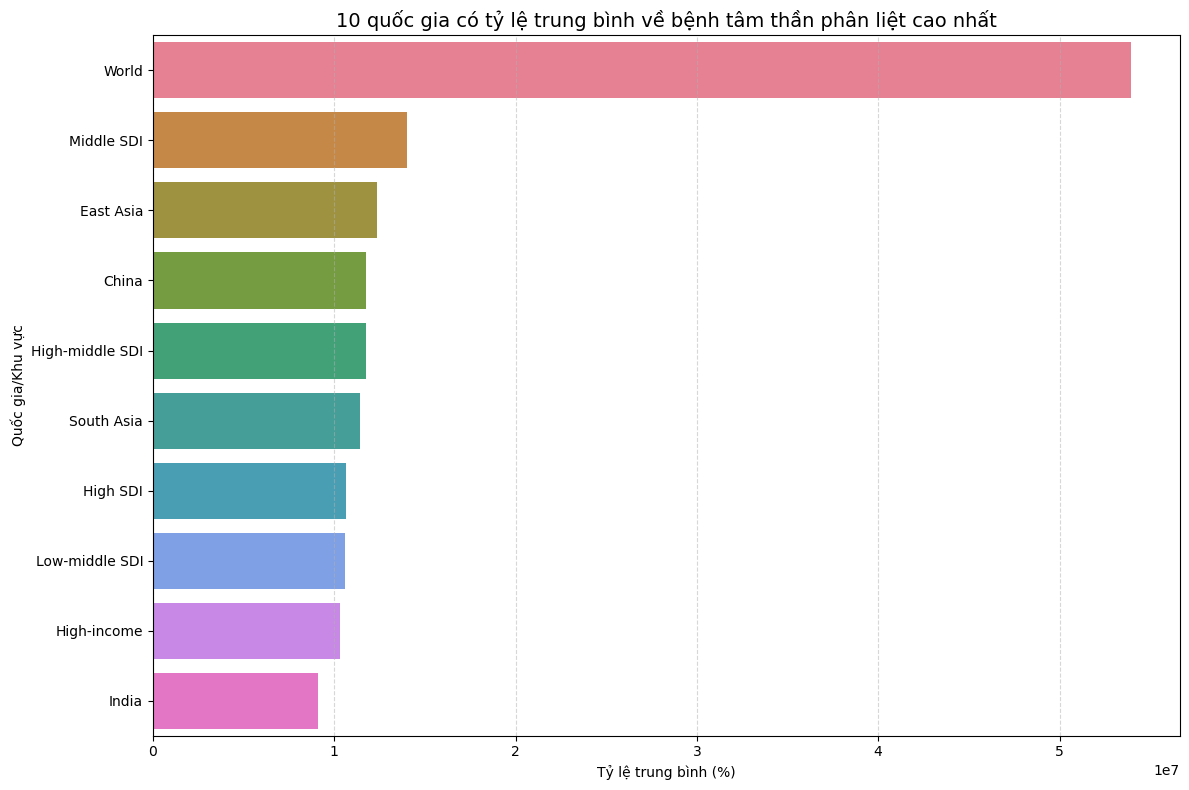

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
# Tính trung bình tỷ lệ tâm thần phân liệt theo quốc gia và chọn top 10
top_Schizophrenia_df = (
    df.groupby('Entity')['Schizophrenia (%)']
    .mean()
    .nlargest(10)
    .reset_index()
)
# Vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Schizophrenia (%)',
    y='Entity',
    data=top_Schizophrenia_df,
    palette='husl'  # Mỗi quốc gia sẽ có một màu khác nhau
)
plt.title('10 quốc gia có tỷ lệ trung bình về bệnh tâm thần phân liệt cao nhất', fontsize=14)
plt.xlabel('Tỷ lệ trung bình (%)')
plt.ylabel('Quốc gia/Khu vực')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("top_10_Schizophrenia_countries.png", dpi=100)
plt.show()


C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\337177789.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


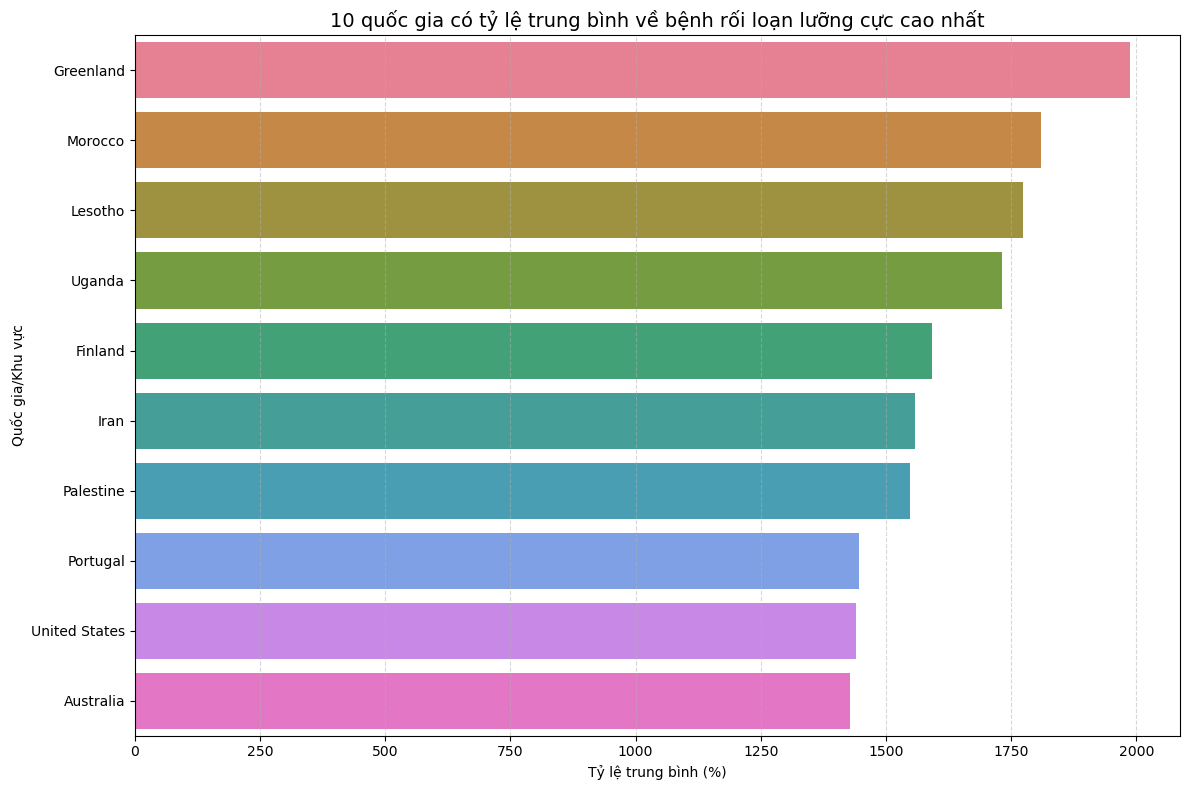

In [17]:
# Tính trung bình tỷ lệ rối loạn lưỡng cực theo quốc gia và chọn top 10
top_Bipolar_df = (
    df.groupby('Entity')['Bipolar disorder (%)']
    .mean()
    .nlargest(10)
    .reset_index()
)
# Vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Bipolar disorder (%)',
    y='Entity',
    data=top_Bipolar_df,
    palette='husl'
)
plt.title('10 quốc gia có tỷ lệ trung bình về bệnh rối loạn lưỡng cực cao nhất', fontsize=14)
plt.xlabel('Tỷ lệ trung bình (%)')
plt.ylabel('Quốc gia/Khu vực')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("top_10_Bipolar_countries.png", dpi=100)
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\1019245240.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


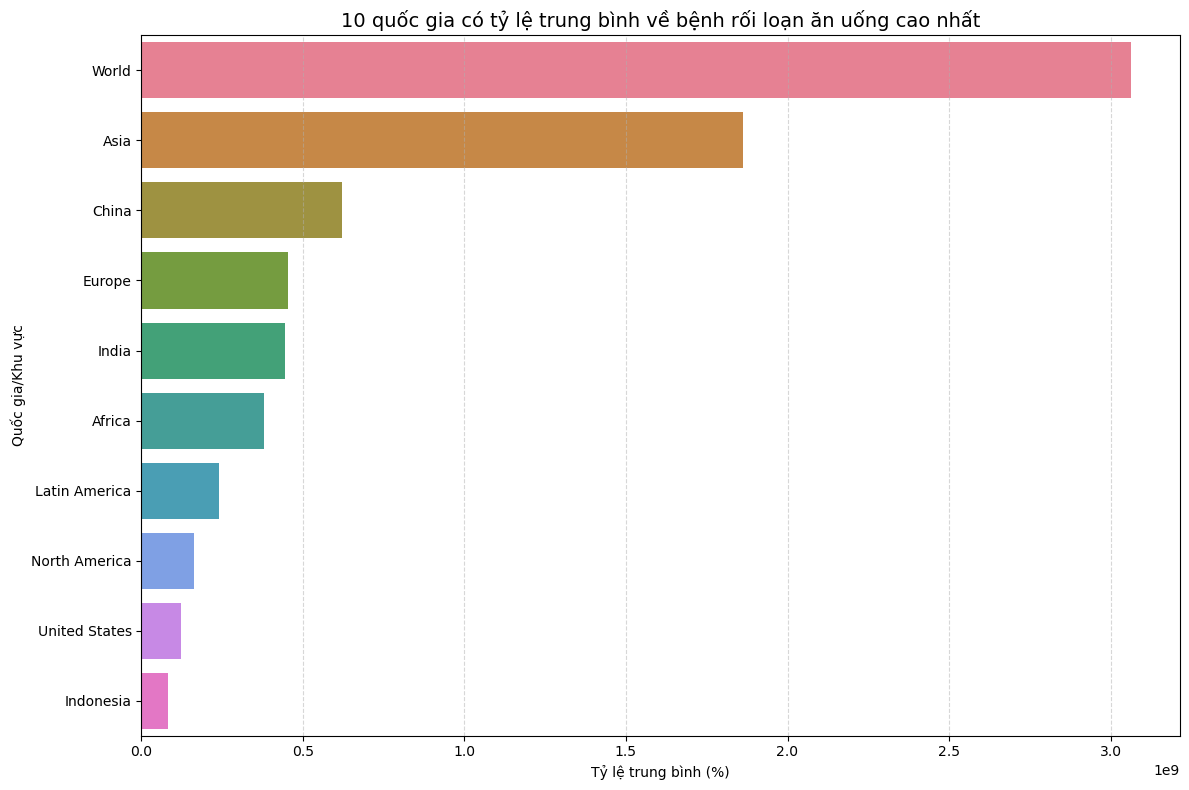

In [18]:
# Tính trung bình tỷ lệ rối loạn ăn uống theo quốc gia và chọn top 10
top_Eating_df = (
    df.groupby('Entity')['Eating disorders (%)']
    .mean()
    .nlargest(10)
    .reset_index()
)
# Vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Eating disorders (%)',
    y='Entity',
    data=top_Eating_df,
    palette='husl'
)
plt.title('10 quốc gia có tỷ lệ trung bình về bệnh rối loạn ăn uống cao nhất', fontsize=14)
plt.xlabel('Tỷ lệ trung bình (%)')
plt.ylabel('Quốc gia/Khu vực')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("top_10_Eating_countries.png", dpi=100)
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\1949412.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


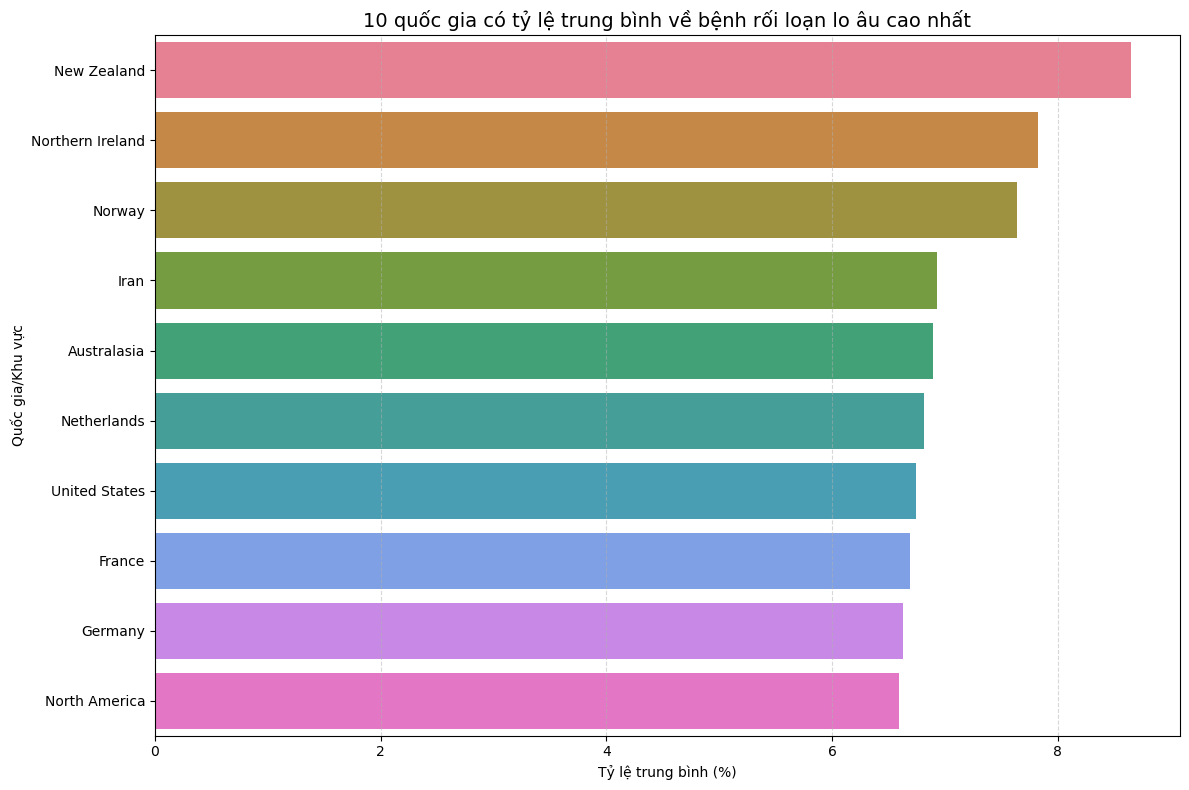

In [19]:
# Tính trung bình tỷ lệ lo âu theo quốc gia và chọn top 10
top_anxiety_df = (
    df.groupby('Entity')['Anxiety disorders (%)']
    .mean()
    .nlargest(10)
    .reset_index()
)
# Vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Anxiety disorders (%)',
    y='Entity',
    data=top_anxiety_df,
    palette='husl'
)
plt.title('10 quốc gia có tỷ lệ trung bình về bệnh rối loạn lo âu cao nhất', fontsize=14)
plt.xlabel('Tỷ lệ trung bình (%)')
plt.ylabel('Quốc gia/Khu vực')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("top_10_anxiety_countries.png", dpi=100)
plt.show()


C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\1573910593.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


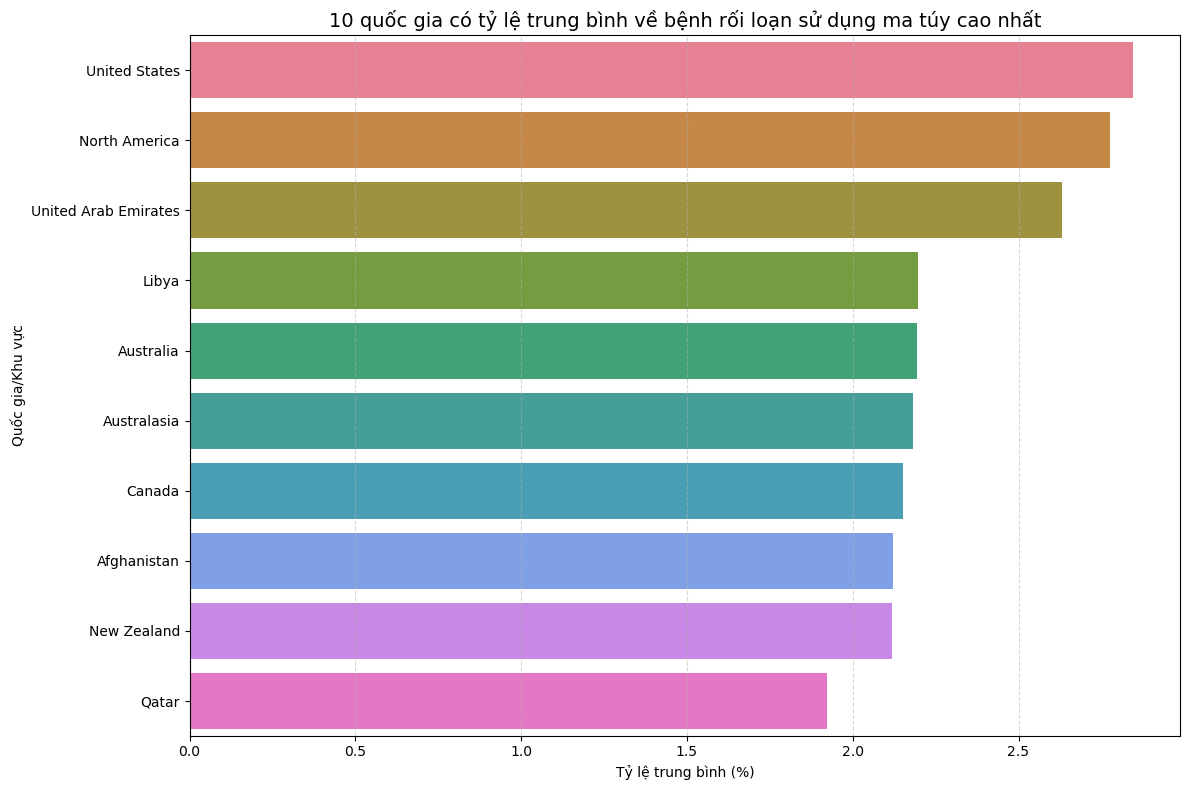

In [20]:
# Tính trung bình tỷ lệ bệnh rối loạn sử dụng ma túy theo quốc gia và chọn top 10
top_Drug_df = (
    df.groupby('Entity')['Drug use disorders (%)']
    .mean()
    .nlargest(10)
    .reset_index()
)
# Vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Drug use disorders (%)',
    y='Entity',
    data=top_Drug_df,
    palette='husl'
)
plt.title('10 quốc gia có tỷ lệ trung bình về bệnh rối loạn sử dụng ma túy cao nhất', fontsize=14)
plt.xlabel('Tỷ lệ trung bình (%)')
plt.ylabel('Quốc gia/Khu vực')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("top_10_Drug_countries.png", dpi=100)
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\4014439585.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


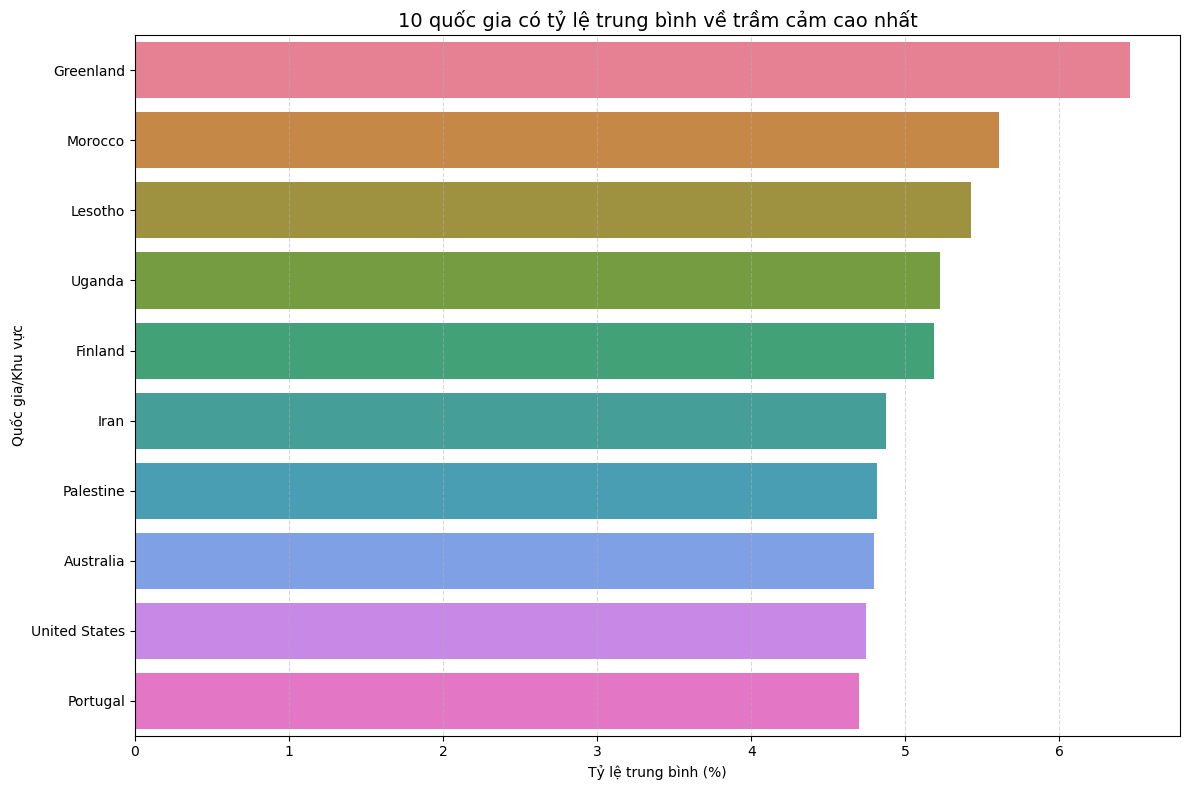

In [21]:
# Tính trung bình tỷ lệ trầm cảm theo quốc gia và chọn top 10
top_Depression_df = (
    df.groupby('Entity')['Depression (%)']
    .mean()
    .nlargest(10)
    .reset_index()
)
# Vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Depression (%)',
    y='Entity',
    data=top_Depression_df,
    palette='husl'
)
plt.title('10 quốc gia có tỷ lệ trung bình về trầm cảm cao nhất', fontsize=14)
plt.xlabel('Tỷ lệ trung bình (%)')
plt.ylabel('Quốc gia/Khu vực')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("top_10_Depression_countries.png", dpi=100)
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\3969051213.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


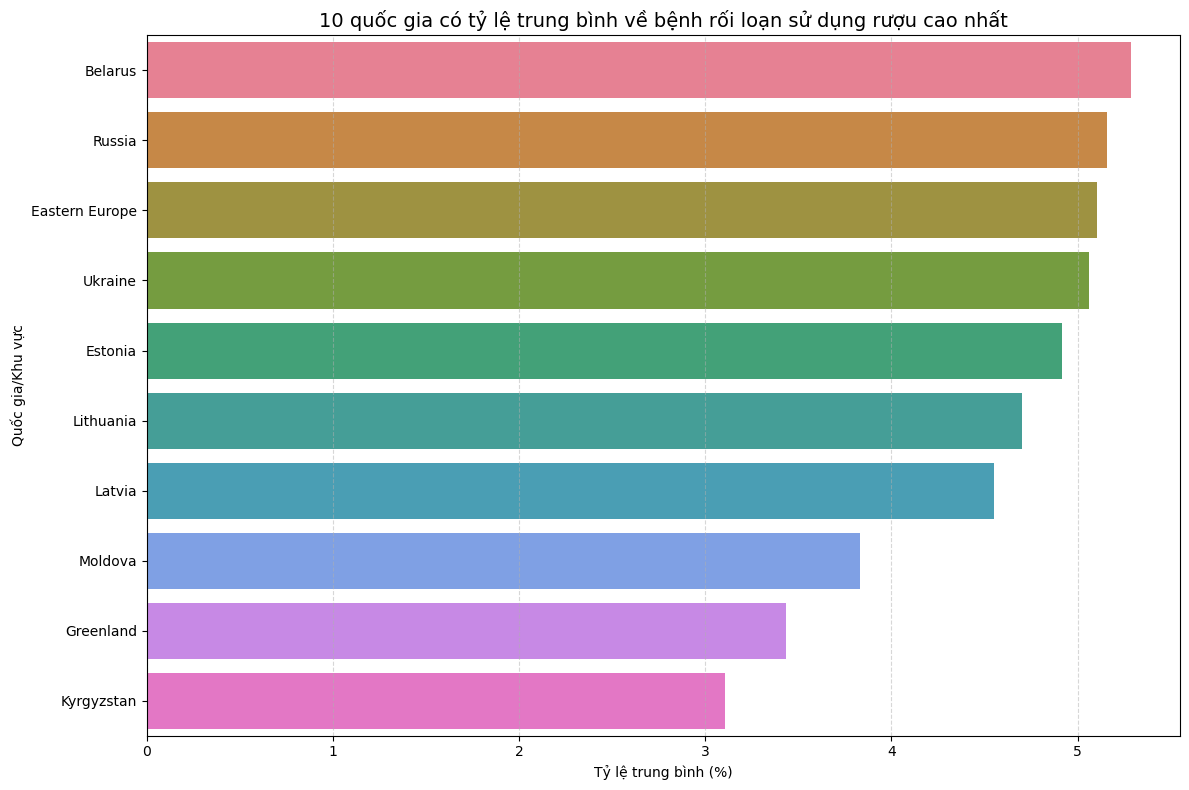

In [22]:
# Tính trung bình tỷ lệ bệnh rối loạn sử dụng rượu theo quốc gia và chọn top 10
top_Alcohol_df = (
    df.groupby('Entity')['Alcohol use disorders (%)']
    .mean()
    .nlargest(10)
    .reset_index()
)
# Vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Alcohol use disorders (%)',
    y='Entity',
    data=top_Alcohol_df,
    palette='husl'
)
plt.title('10 quốc gia có tỷ lệ trung bình về bệnh rối loạn sử dụng rượu cao nhất', fontsize=14)
plt.xlabel('Tỷ lệ trung bình (%)')
plt.ylabel('Quốc gia/Khu vực')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("top_10_Alcohol_countries.png", dpi=100)
plt.show()

Qua việc phân dữ liệu ở trên cho thấy được sự phát triển của xã hội đi kèm với những mối lo lắng, khiến cho nhiều người ngày càng chịu nhiều hơn các bệnh về tâm lý và tinh thần. Thế cho nên cần phải chú trọng hơn vào chăm sóc sức khỏe tinh thần cho mọi người nói chung.

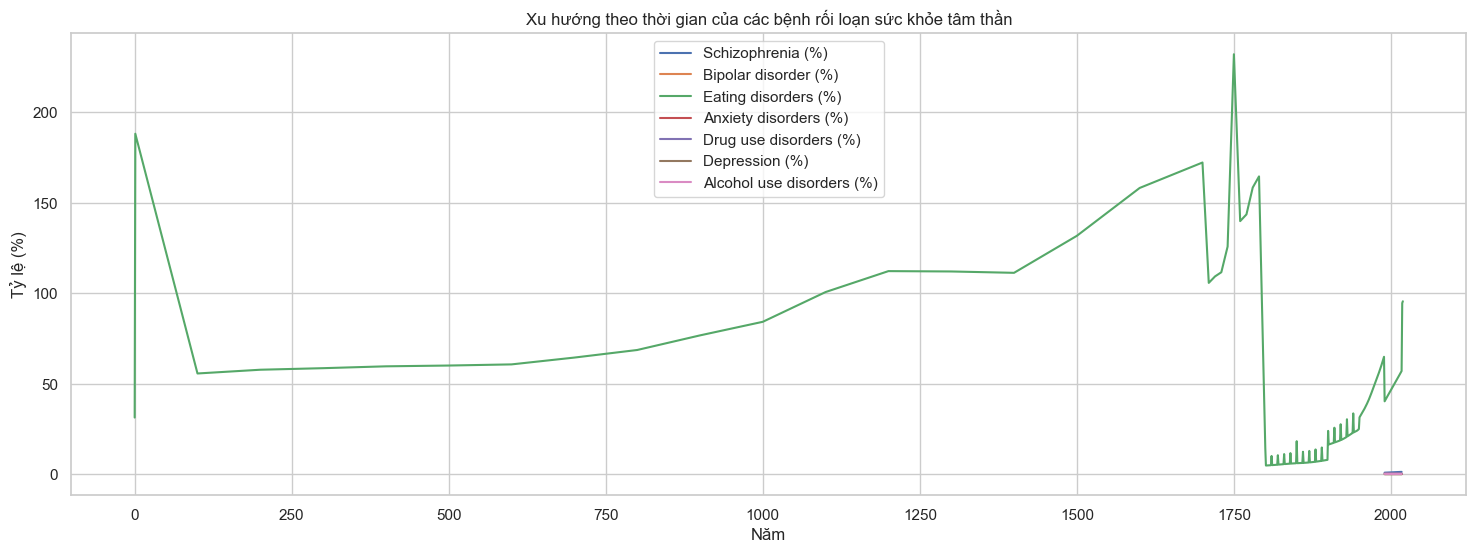

In [32]:
#Trực quan hóa các xu hướng tạm thời trong sự phổ biến của các rối loạn sức khỏe tâm thần khác nhau theo từng năm.
columns_of_interest = ["Year", "Schizophrenia (%)", "Bipolar disorder (%)", "Eating disorders (%)", "Anxiety disorders (%)", "Drug use disorders (%)", "Depression (%)", "Alcohol use disorders (%)"]
df_selected = df[columns_of_interest]
df_yearly_mean = df_selected.groupby("Year").mean()
plt.figure(figsize=(18,6))
for column in df_yearly_mean.columns:
    plt.plot(df_yearly_mean.index, df_yearly_mean[column], label=column)

plt.xlabel("Năm")
plt.ylabel("Tỷ lệ (%)")
plt.title("Xu hướng theo thời gian của các bệnh rối loạn sức khỏe tâm thần")
plt.legend()
plt.grid(True)
plt.savefig("xu_huong.png", dpi=100)
plt.show()

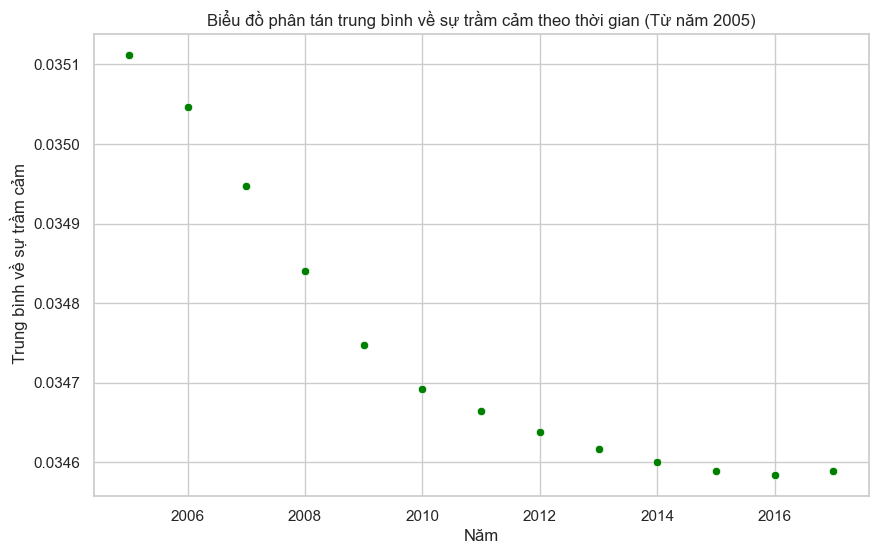

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Chọn cột liên quan, xử lý dữ liệu
selected_columns = ['Year', 'Depression (%)']
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df['Depression (%)'] = pd.to_numeric(df['Depression (%)'], errors='coerce')

# Lọc các hàng có giá trị bị thiếu và lọc các năm bắt đầu từ 2005.
selected_data =df[selected_columns].dropna()
filtered_data = selected_data[selected_data['Year'] >= 2005]

# Tính giá trị trung bình cho mỗi năm
mean_data = filtered_data.groupby('Year').mean().reset_index()
sns.set(style="whitegrid")

# Tạo một biểu đồ phân tán
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Year', y='Depression (%)', data=mean_data, color='green')

plt.title('Biểu đồ phân tán trung bình về sự trầm cảm theo thời gian (Từ năm 2005)')
plt.xlabel('Năm')
plt.ylabel(' Trung bình về sự trầm cảm')
plt.savefig("phan_tan_tram_cam.png", dpi=100)
plt.show()

##### * Có thể thấy ở đây, trong những năm qua, số ca trầm cảm đã giảm.

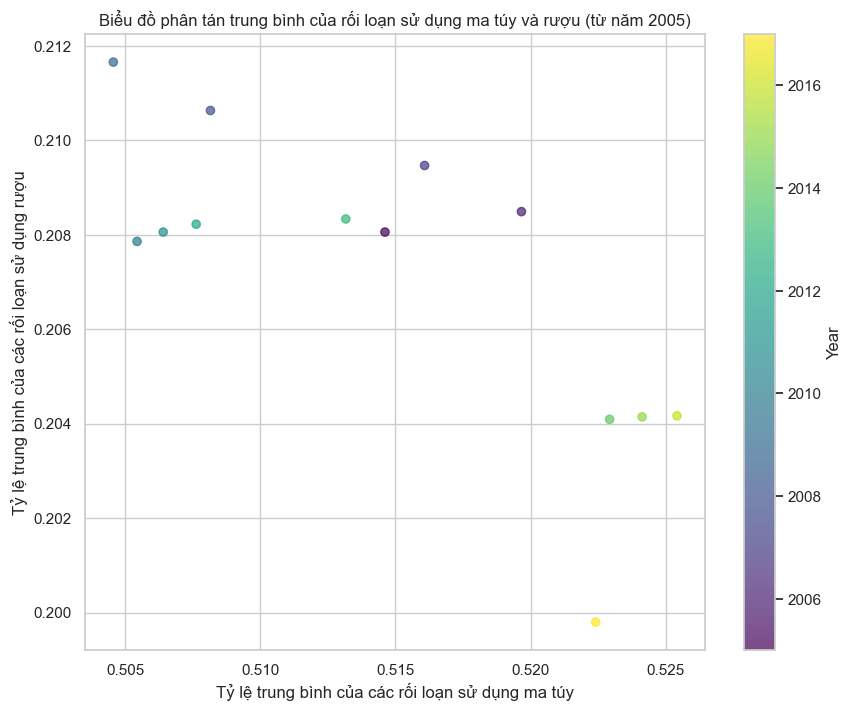

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

#Lựa chọn các cột 'Year', 'Drug use disorders (%)', 'Alcohol use disorders (%)
columns_to_plot = ['Year', 'Drug use disorders (%)', 'Alcohol use disorders (%)']

# Chuyển đổi các cột phần trăm thành số
for col in columns_to_plot:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Lọc dữ liệu cho các năm từ 2005 trở đi
filtered_data = df[df['Year'] >= 2005]

# Loại bỏ các hàng có giá trị bị thiếu trong các cột liên quan
filtered_data = filtered_data.dropna(subset=columns_to_plot[1:])

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
scaled_data = scaler.fit_transform(filtered_data[columns_to_plot[1:]])

# Tính trung bình cho mỗi rối loạn cho mỗi năm
mean_data = filtered_data.groupby('Year')[columns_to_plot[1:]].mean().reset_index()

# Tạo một biểu đồ phân tán cho việc sử dụng ma túy so với việc sử dụng rượu.
plt.figure(figsize=(10, 8))
plt.scatter(mean_data['Drug use disorders (%)'], mean_data['Alcohol use disorders (%)'],
            c=mean_data['Year'], cmap='viridis', alpha=0.7)

plt.xlabel('Tỷ lệ trung bình của các rối loạn sử dụng ma túy')
plt.ylabel('Tỷ lệ trung bình của các rối loạn sử dụng rượu')
plt.title('Biểu đồ phân tán trung bình của rối loạn sử dụng ma túy và rượu (từ năm 2005)')
plt.colorbar(label='Year')
plt.grid(True)
plt.savefig("ruou_matuy.png", dpi=100)
plt.show()

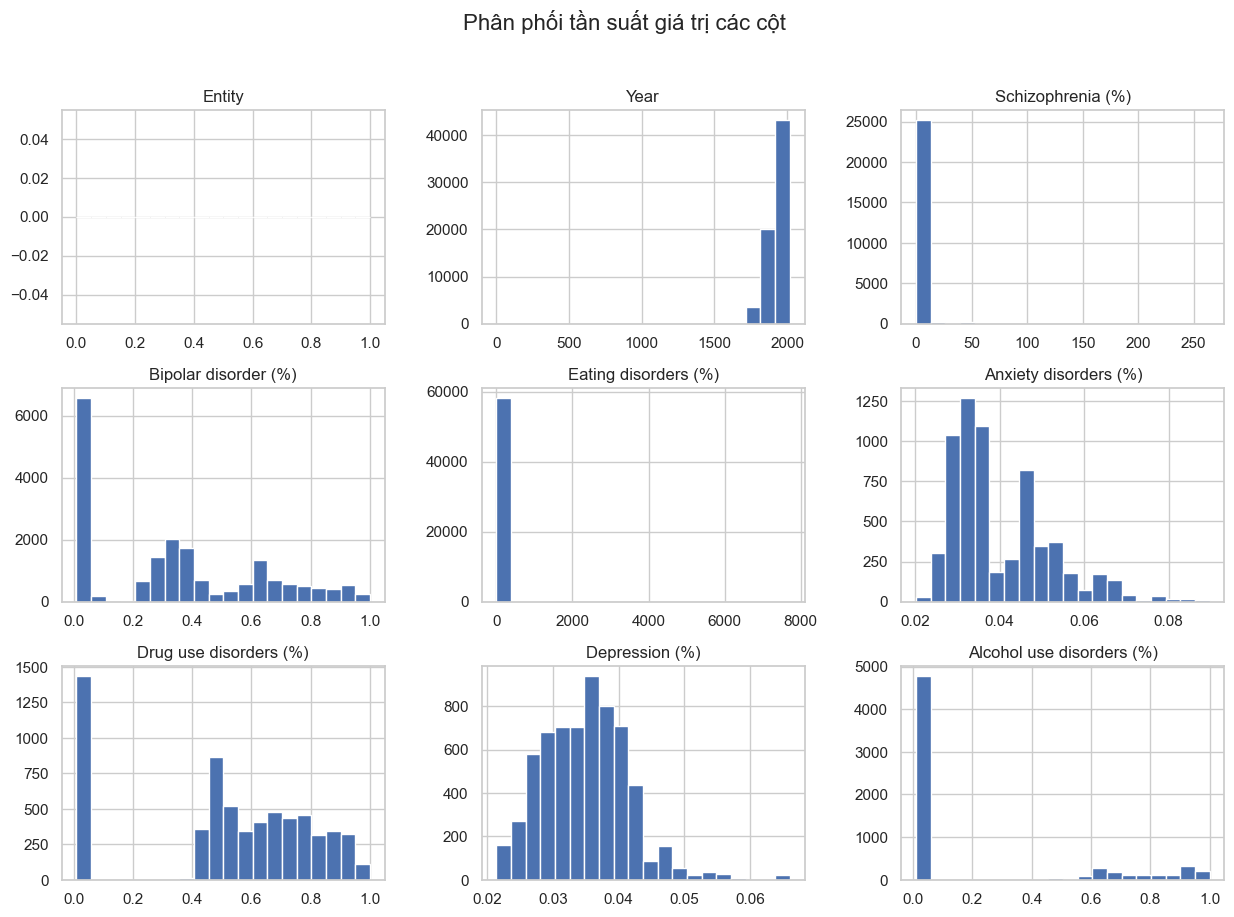

In [41]:
#Vẽ histogram cho các cột số để trực quan hóa phân phối dữ liệu
df.hist(figsize=(15, 10), bins=20)
plt.suptitle('Phân phối tần suất giá trị các cột', fontsize=16) #Trục y: số lượng quốc gia, trục x: tỷ lệ %
plt.savefig("tan_suat.png", dpi=90)
plt.show()

*	Schizophrenia (%): Phần lớn các giá trị tập trung gần 0 -10, chỉ một số cực ít điểm có giá trị cao bất thường (outlier). Điều này cho thấy tỷ lệ tâm thần phân liệt nhìn chung thấp ở các quốc gia/khu vực
*	Bipolar disorder (%): Có cột hiện rõ rệt ở giá trị gần 0 và phân phối rải rác từ 0.2 đến 1.0. Tỷ lệ rối loạn lưỡng cực khá đa dạng giữa các quốc gia/khu vực.
*	Eating disorders (%): Hầu hết giá trị nằm gần 0
*	Anxiety disorders (%):  Giá trị tập trung ở hai nhóm 0.02-0.06 và 0.08
*	Drug use disorders (%):  Một nhóm gần 0, Một nhóm ở khoảng 0.5-0.8
*	Depression (%): Tập trung chủ yếu ở khoảng 0.03-0.04. Cho thấy trầm cảm là bệnh khá phổ biến và mức độ ảnh hưởng khá đồng đều
*	Alcohol use disorders (%): Hầu hết tập trung gần 0, bất ngờ một số nhỏ quốc gia/khu vực có giá trị cao trong khoảng 0.6-1.0


#### Correlation Coefficient (Hệ số tương quan)

Sự tương quan giữa các loại rối loạn tâm thần khác nhau

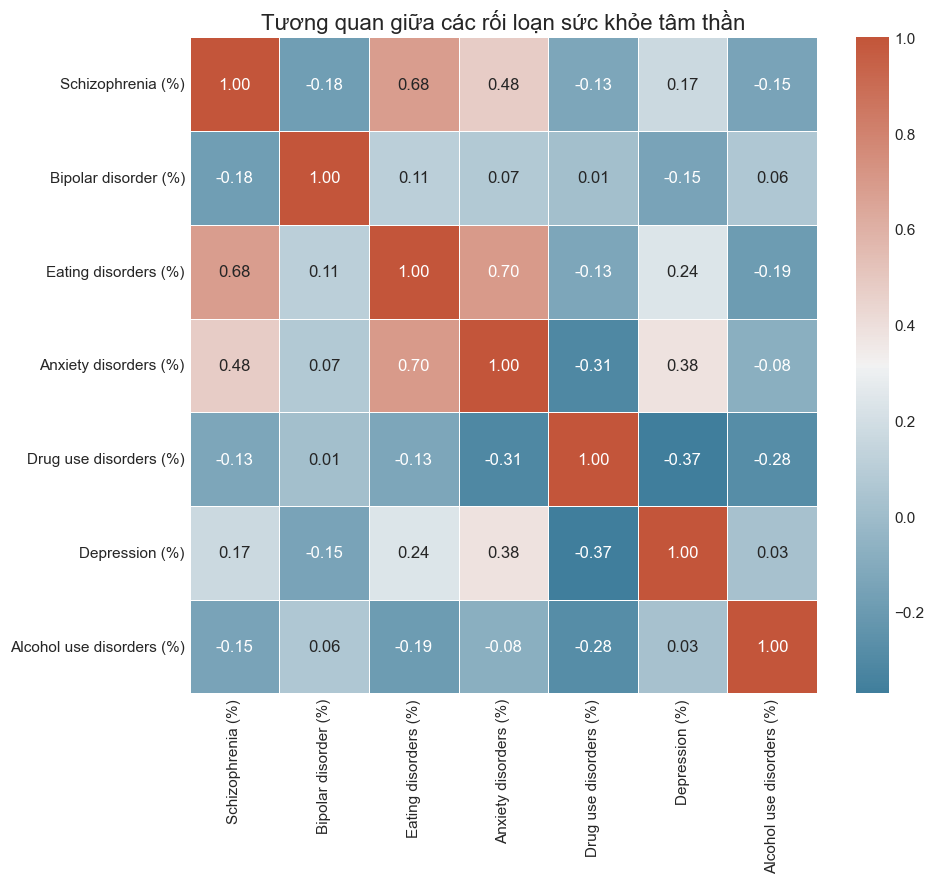

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ví dụ: danh sách các cột muốn lấy
cols = [
    'Schizophrenia (%)', 'Bipolar disorder (%)', 'Eating disorders (%)',
    'Anxiety disorders (%)', 'Drug use disorders (%)', 'Depression (%)',
    'Alcohol use disorders (%)'
]

# Chọn ra các cột có trong df
selected_data = df[[col for col in cols if col in df.columns]]

# Ép kiểu dữ liệu sang số
selected_data = selected_data.apply(pd.to_numeric, errors='coerce')

# Xóa dòng có giá trị NaN ở bất kỳ cột nào
selected_data = selected_data.dropna()

# Tính ma trận tương quan
corr_matrix = selected_data.corr().round(2)

# Vẽ heatmap
plt.figure(figsize=(10, 9), dpi=100)
sns.heatmap(
    data=corr_matrix,
    annot=True,
    cmap=sns.diverging_palette(230, 20, as_cmap=True),
    fmt=".2f",
    linewidths=0.5,
    annot_kws={"size": 12}
)

plt.title("Tương quan giữa các rối loạn sức khỏe tâm thần", fontsize=16)
plt.tight_layout()
plt.savefig("tquan.png", dpi=90)
plt.show()


##### Màu ấm (tương quan dương): cho thấy rằng khi một biến tăng thì biến kia cũng tăng theo
##### Màu mát (tương quan âm): cho thấy rằng khi một biến tăng thì biến kia giảm đi

1. Các mối tương quan mạnh (r > 0.6):
* Schizophrenia (%) & Eating disorders (%): r = 0.68 → Tương quan dương mạnh. Những nơi có tỷ lệ tâm thần phân liệt cao thường có tỷ lệ rối loạn ăn uống cao.
* Eating disorders (%) & Anxiety disorders (%): r = 0.70 → Tương quan dương mạnh. Các quốc gia có tỷ lệ rối loạn ăn uống cao cũng thường có tỷ lệ rối loạn lo âu cao.
2. Các mối tương quan trung bình (0.3 ≤ r ≤ 0.6):
* Schizophrenia (%) & Anxiety disorders (%): r = 0.48 → Tương quan dương trung bình.
* Anxiety disorders (%) & Depression (%): r = 0.38 → Tương quan dương trung bình.
3. Các mối tương quan âm đáng chú ý:
* Drug use disorders (%) & Depression (%): r = -0.37 → Tương quan âm trung bình. Khi tỷ lệ rối loạn sử dụng ma túy tăng thì tỷ lệ trầm cảm có xu hướng giảm (hoặc ngược lại).
* Drug use disorders (%) & Anxiety disorders (%): r = -0.31 → Tương quan âm trung bình.
4. Các mối tương quan yếu hoặc gần như không đáng kể (r < 0.3): Phần lớn các cặp còn lại có hệ số tương quan nhỏ, cho thấy mối liên hệ không rõ ràng.

* Những mối tương quan lớn nhất là:
  - tâm thần phân liệt + rối loạn ăn uống -> 0.68
  - rối loạn lưỡng cực + rối loạn ăn uống -> 0.7
  - rối loạn lo âu + rối loạn ăn uống -> 0.7
  - rối loạn lo âu + (rối loạn lưỡng cực / rối loạn sử dụng ma túy) -> 0.66 / 0.62
 * Như bạn có thể thấy, rối loạn ăn uống có khả năng cao ở bệnh nhân mắc tâm thần phân liệt / rối loạn lưỡng cực / rối loạn lo âu. Vậy hãy xem những mối tương quan đó.

##### Mối tương quan tích cực giữa rối loạn ăn uống và tâm thần phân liệt / lưỡng cực / lo âu.

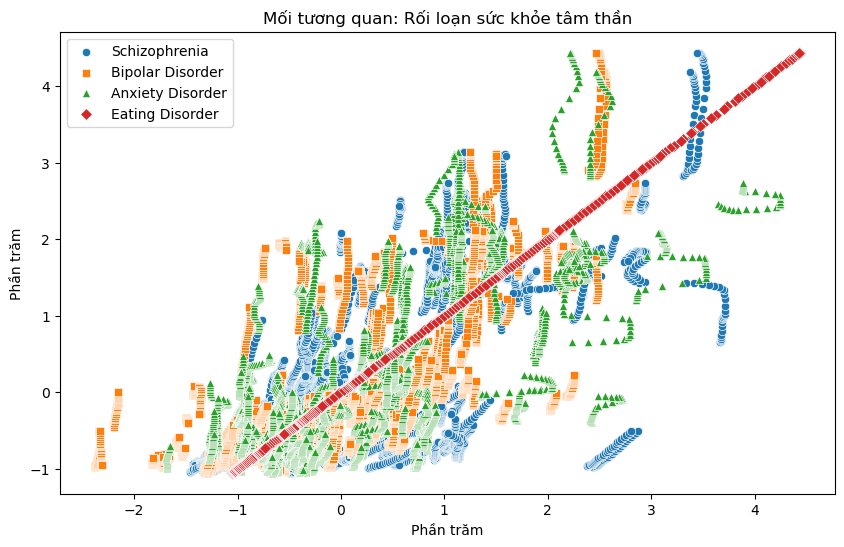

In [120]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Trích xuất các cột liên quan cho biểu đồ phân tán
mental_health_subset = df[[
    'Schizophrenia (%)',
    'Bipolar disorder (%)',
    'Anxiety disorders (%)',
    'Eating disorders (%)'
]]

# Loại bỏ tất cả các hàng có giá trị bị thiếu (nếu có)
mental_health_subset = mental_health_subset.dropna()

# Chuẩn hóa các giá trị bằng cách sử dụng StandardScaler
scaler = StandardScaler()
mental_health_scaled = pd.DataFrame(scaler.fit_transform(mental_health_subset), columns=mental_health_subset.columns)
plt.figure(figsize=(10, 6))
# Biểu đồ tán xạ cho tất cả các rối loạn trên cùng một biểu đồ
sns.scatterplot(x='Schizophrenia (%)', y='Eating disorders (%)', data=mental_health_scaled, label='Schizophrenia', marker='o')
sns.scatterplot(x='Bipolar disorder (%)', y='Eating disorders (%)', data=mental_health_scaled, label='Bipolar Disorder', marker='s')
sns.scatterplot(x='Anxiety disorders (%)', y='Eating disorders (%)', data=mental_health_scaled, label='Anxiety Disorder', marker='^')
sns.scatterplot(x='Eating disorders (%)', y='Eating disorders (%)', data=mental_health_scaled, label='Eating Disorder', marker='D')

plt.title('Mối tương quan: Rối loạn sức khỏe tâm thần')
plt.xlabel('Phần trăm')
plt.ylabel('Phần trăm')
plt.legend()
plt.show()

### Clustering (Gom cụm)


Chuẩn bị dữ liệu:  Tách DataFrame thành các DataFrame như sau, theo mức độ phổ biến và mức độ liên quan:
1. Rối loạn lo âu và trầm cảm (Anxiety disorders,Depression ): là hai rối loạn phổ biến nhất, ảnh hưởng đến một lượng lớn dân số.
2. Rối loạn ăn uống, rối loạn sử dụng ma túy, rối loạn sử dụng rượu (Eating disorders,Drug use disorders,Alcohol use disorders): khá phổ biến, đặc biệt trong các nhóm tuổi trẻ.

In [60]:
#Chuẩn bị dữ liệu
# Tách DataFrame df thành ba dataframe 
df_1=df[["Entity","Year","Anxiety disorders (%)","Depression (%)"]]
df_2=df[["Entity","Year","Eating disorders (%)","Drug use disorders (%)","Alcohol use disorders (%)"]]
print('---DataFrame 1---')
df_1.info()
print('---DataFrame 2---')
df_2.info()

---DataFrame 1---
<class 'pandas.core.frame.DataFrame'>
Index: 66989 entries, 0 to 108552
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Entity                 0 non-null      float64
 1   Year                   66917 non-null  float64
 2   Anxiety disorders (%)  6412 non-null   float64
 3   Depression (%)         6412 non-null   float64
dtypes: float64(4)
memory usage: 4.6+ MB
---DataFrame 2---
<class 'pandas.core.frame.DataFrame'>
Index: 66989 entries, 0 to 108552
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Entity                     0 non-null      float64
 1   Year                       66917 non-null  float64
 2   Eating disorders (%)       58839 non-null  float64
 3   Drug use disorders (%)     6412 non-null   float64
 4   Alcohol use disorders (%)  6412 non-null   float64
dtypes: flo

In [61]:
# Lọc ra các cột cần tính toán
df_1=df_1[["Anxiety disorders (%)","Depression (%)"]]
df_1.info()
df_2=df_2[["Eating disorders (%)","Drug use disorders (%)","Alcohol use disorders (%)"]]
df_2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 66989 entries, 0 to 108552
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Anxiety disorders (%)  6412 non-null   float64
 1   Depression (%)         6412 non-null   float64
dtypes: float64(2)
memory usage: 3.5+ MB
<class 'pandas.core.frame.DataFrame'>
Index: 66989 entries, 0 to 108552
Data columns (total 3 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Eating disorders (%)       58839 non-null  float64
 1   Drug use disorders (%)     6412 non-null   float64
 2   Alcohol use disorders (%)  6412 non-null   float64
dtypes: float64(3)
memory usage: 4.1+ MB


In [62]:
# Tiền xử lý dữ liệu thiếu -> điền NA vào ô không có dữ liệu
df_1.fillna(df_1.mean(), inplace=True)

### K-Means

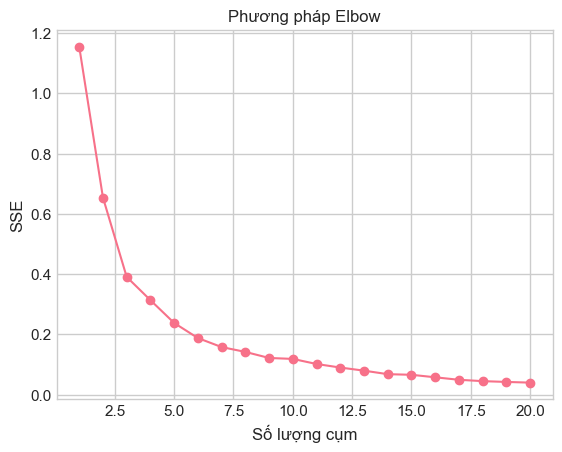

In [64]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Tìm số cụm tối ưu sử dụng phương pháp Elbow
max_clusters = 20 # Số cụm tối đa muốn xem
sse = []
for k in range(1, max_clusters + 1):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_1)
    sse.append(kmeans.inertia_)

# Vẽ biểu đồ Elbow
plt.plot(range(1, max_clusters + 1), sse, marker='o')
plt.xlabel('Số lượng cụm')
plt.ylabel('SSE')
plt.title('Phương pháp Elbow')
plt.savefig("elbow.png", dpi=90)
plt.show()

* Theo phương pháp Elbow, chúng ta trải nghiệm một xu hướng gần như nằm ngang từ 5 cụm trở đi, điều này có nghĩa là độ dốc lớn của xu hướng biến mất và điều này chỉ ra rằng số lượng cụm phù hợp để phân cụm trong tập dữ liệu này

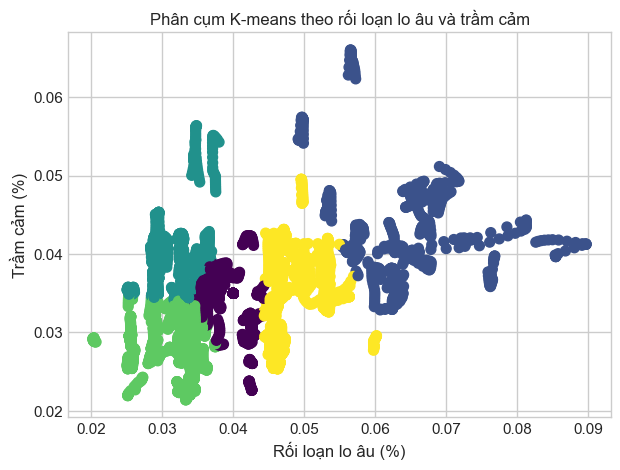

In [65]:
# Số cụm tối ưu dựa trên biểu đồ Elbow
num_clusters = 5

# Áp dụng thuật toán K-means
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
kmeans.fit(df_1)

# Gán nhãn cụm cho dữ liệu
df_1['Cluster'] = kmeans.labels_

# Trực quan hóa theo 2 đặc trưng
plt.figure(figsize=(7,5))
plt.scatter(df_1['Anxiety disorders (%)'], df_1['Depression (%)'],
            c=df_1['Cluster'], cmap='viridis', s=50)
plt.xlabel('Rối loạn lo âu (%)')
plt.ylabel('Trầm cảm (%)')
plt.title('Phân cụm K-means theo rối loạn lo âu và trầm cảm')
plt.grid(True)
plt.savefig("kmeans.png", dpi=90)
plt.show()

Số lượng cụm: Biểu đồ cho thấy dữ liệu được phân thành 5 cụm (được thể hiện bằng 5 màu điểm khác nhau).
Phân bố cụm theo rối loạn lo âu và trầm cảm:
* Cụm bên trái (với điểm thấp về rối loạn lo âu, khoảng 2-4%) có mức trầm cảm dao động từ khoảng 2% đến 5%, trong đó có một số điểm trầm cảm thấp và một số điểm trầm cảm cao hơn.
* Cụm ở giữa với mức rối loạn lo âu trung bình (khoảng 4-6%) có mức trầm cảm cũng đa dạng nhưng tập trung chủ yếu khoảng 3-5%.
* Cụm ở bên phải (với rối loạn lo âu cao hơn, khoảng 6-9%) có mức trầm cảm cũng ở mức trung bình đến cao (khoảng 3-5%).
Mức độ phân tách cụm: Các cụm được phân tách khá rõ ràng, không bị chồng lấn quá nhiều.
Ý nghĩa thực tiễn:
* Cụm rối loạn lo âu thấp, trầm cảm thấp có thể đại diện cho nhóm người ít bị ảnh hưởng.
* Cụm rối loạn lo âu và trầm cảm cao hơn có thể đại diện nhóm bệnh nhân cần chú ý nhiều hơn.

#### Phân cụm với rối loạn sử dụng ma túy, rối loạn sử dụng rượu

In [66]:
# Tiền xử lý dữ liệu thiếu -> điền NA vào ô không có điểm thi
df_2.fillna(df_1.mean(), inplace=True)

In [67]:
df_2[["Drug use disorders (%)","Alcohol use disorders (%)"]].round(2)

,Drug use disorders (%),Alcohol use disorders (%)
index,,
0,0.02,0.67
1,0.02,0.67
2,0.02,0.67
3,0.02,0.67
4,0.02,0.67
...,...,...
108548,NaN,NaN
108549,NaN,NaN
108550,NaN,NaN


Center found by scikit-learn:
 [[0.57369004 0.86605759]
 [0.79986801 0.02402306]
 [0.01596187 0.66731749]
 [0.01545531 0.01945224]
 [0.53235734 0.01862392]]


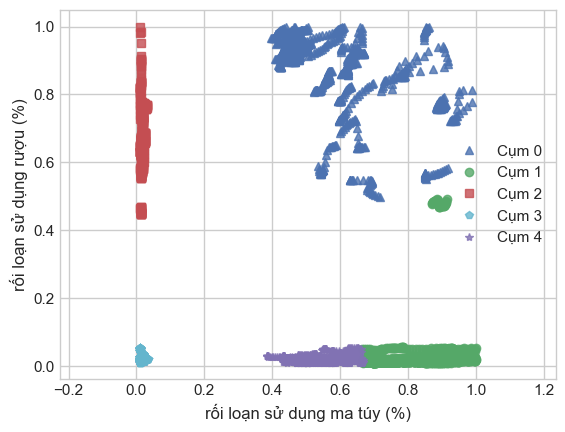

In [70]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def kmeans_display(X, label):
    K = np.amax(label) + 1
    colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k']
    markers = ['^', 'o', 's', 'p', '*', 'x', 'd']

    for k in range(K):
        Xk = X[label == k, :]
        plt.plot(Xk[:, 0], Xk[:, 1], markers[k], color=colors[k], markersize=6, alpha=0.8, label=f'Cụm {k}')

    plt.xlabel("rối loạn sử dụng ma túy (%)")
    plt.ylabel("rối loạn sử dụng rượu (%)")
    plt.legend()
    plt.axis('equal')
    plt.grid(True)
    plt.savefig("kmeans2.png", dpi=90)
    plt.show()

# Loại bỏ các dòng có giá trị NaN trong cột phân cụm
df_clean = df_2.dropna(subset=["Drug use disorders (%)", "Alcohol use disorders (%)"])

num_clusters = 5

X = df_clean[["Drug use disorders (%)", "Alcohol use disorders (%)"]].values

kmeans = KMeans(n_clusters=num_clusters, random_state=0)
kmeans.fit(X)

print("Center found by scikit-learn:\n", kmeans.cluster_centers_)

pred_label = kmeans.predict(X)

kmeans_display(X, pred_label)


Số cụm (clusters): Có 5 cụm được phân tách, được đánh dấu bằng các ký hiệu và màu sắc khác nhau (tam giác xanh, tròn xanh lá, vuông đỏ, kim cương xanh dương, sao hồng).
Phân bố dữ liệu:
* Cụm 0 (tam giác xanh) tập trung ở vùng có tỉ lệ rối loạn sử dụng ma túy thấp (khoảng dưới 1%) và rối loạn sử dụng rượu thấp (dưới 1.5%).
* Cụm 1 (chấm xanh lá) có tỉ lệ rối loạn sử dụng rượu cao hơn (khoảng 4-5%), nhưng tỉ lệ rối loạn sử dụng ma túy vẫn khá thấp (khoảng 0.7-1%).
* Cụm 2 (vuông đỏ) nằm ở vùng có tỉ lệ rối loạn sử dụng ma túy và rượu trung bình, khoảng 0.7-1.5% và 2-3.5% tương ứng.
* Cụm 3 (kim cương xanh dương) có tỉ lệ rối loạn sử dụng ma túy cao nhất (khoảng 1.5-3.5%), nhưng tỉ lệ rối loạn sử dụng rượu lại thấp (khoảng 0.8-2%).
* Cụm 4 (sao hồng) nằm gần vùng tỉ lệ thấp của cả hai biến, giống cụm 0 nhưng có thể nằm giữa cụm 0 và cụm 2.
Phân biệt cụm: Các cụm nhìn chung được phân tách khá rõ ràng theo tỉ lệ rối loạn sử dụng ma túy và rượu, tuy có một số cụm gần nhau và có sự chồng lấn nhẹ (như cụm 0 và 4).
Ý nghĩa:
* Phân cụm này có thể hữu ích để nhận dạng nhóm dân số hoặc nhóm bệnh nhân theo mức độ rối loạn sử dụng ma túy và rượu.
* Một số cụm có thể biểu thị nhóm người sử dụng rượu nhiều hơn ma túy (ví dụ cụm 1), trong khi cụm khác có thể biểu thị nhóm người sử dụng ma túy cao hơn (cụm 3).

### Classification (Phân lớp)

Yêu cầu:
* Sử dụng lại tập tin các rối loạn sức khỏe tâm thần. Bổ sung thêm cột: Trung bình tỷ lệ các bệnh rối loạn sức khỏe và Mức độ quan tâm (rất cao, cao, trung bình,thấp), sau đó tính tóan để điền thông tin:
 - Trung bình tỷ lệ của các bệnh rối loạn sức khỏe = Tổng tỷ lệ các bệnh rối loạn sức khỏe/Tổng số các loại bệnh rối loạn sức khỏe
 -Xếp loại các mức độ quan tâm
 Mức rất cao: tỷ lệ trung bình từ 5% trở lên
 Mức Cao: tỷ lệ trung bình từ 1% trở lên dưới 5%
 Mức Trung bình: tỷ lệ trung bình từ 0.5% đến 1%
 Mức thấp: dưới 0.5%

Sử dụng thuật toán KNN,Naive Bayes để xem kết quả xếp loại mức độ trong tập tin Test có đúng/tốt hay không?

In [77]:
# Đọc dữ liệu từ file health.csv
df = pd.read_csv("health.csv")
df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')
# Tính trung bình tỷ lệ các bệnh rối loạn
df['Trung_binh_ty_le'] = df[cols].mean(axis=1).round(2)
# Loại bỏ các dòng bị thiếu dữ liệu
df = df.dropna()
# Hàm phân loại mức độ quan tâm
def xep_muc_do(tl):
    if tl >= 5:
        return 'Rất cao'
    elif tl >= 1:
        return 'Cao'
    elif tl >= 0.5:
        return 'Trung bình'
    else:
        return 'Thấp'
# Áp dụng phân loại mức độ quan tâm
df['Muc_do_quan_tam'] = df['Trung_binh_ty_le'].apply(xep_muc_do)
# Xuất file kết quả
df.to_csv('df_muc_do.csv', index=False)
df


C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\1966676824.py:2: DtypeWarning: Columns (5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("health.csv")


,index,Entity,Code,Year,Schizophrenia (%),Bipolar disorder (%),Eating disorders (%),Anxiety disorders (%),Drug use disorders (%),Depression (%),Alcohol use disorders (%),Trung_binh_ty_le,Muc_do_quan_tam
0,0,Afghanistan,AFG,1990,0.160560,0.697779,0.101855,4.828830,1.677082,4.071831,0.672404,1.74,Cao
1,1,Afghanistan,AFG,1991,0.160312,0.697961,0.099313,4.829740,1.684746,4.079531,0.671768,1.75,Cao
2,2,Afghanistan,AFG,1992,0.160135,0.698107,0.096692,4.831108,1.694334,4.088358,0.670644,1.75,Cao
3,3,Afghanistan,AFG,1993,0.160037,0.698257,0.094336,4.830864,1.705320,4.096190,0.669738,1.75,Cao
4,4,Afghanistan,AFG,1994,0.160022,0.698469,0.092439,4.829423,1.716069,4.099582,0.669260,1.75,Cao
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6463,6463,Zimbabwe,ZWE,2013,0.155670,0.607993,0.117248,3.090168,0.766280,3.128192,1.515641,1.34,Cao
6464,6464,Zimbabwe,ZWE,2014,0.155993,0.608610,0.118073,3.093964,0.768914,3.140290,1.515470,1.34,Cao
6465,6465,Zimbabwe,ZWE,2015,0.156465,0.609363,0.119470,3.098687,0.771802,3.155710,1.514751,1.35,Cao
6466,6466,Zimbabwe,ZWE,2016,0.157111,0.610234,0.121456,3.104294,0.772275,3.174134,1.513269,1.35,Cao


Naive Bayes Report:
               precision    recall  f1-score   support

         Cao       1.00      1.00      1.00      1098

    accuracy                           1.00      1098
   macro avg       1.00      1.00      1.00      1098
weighted avg       1.00      1.00      1.00      1098

KNN Report:
               precision    recall  f1-score   support

         Cao       1.00      1.00      1.00      1098

    accuracy                           1.00      1098
   macro avg       1.00      1.00      1.00      1098
weighted avg       1.00      1.00      1.00      1098



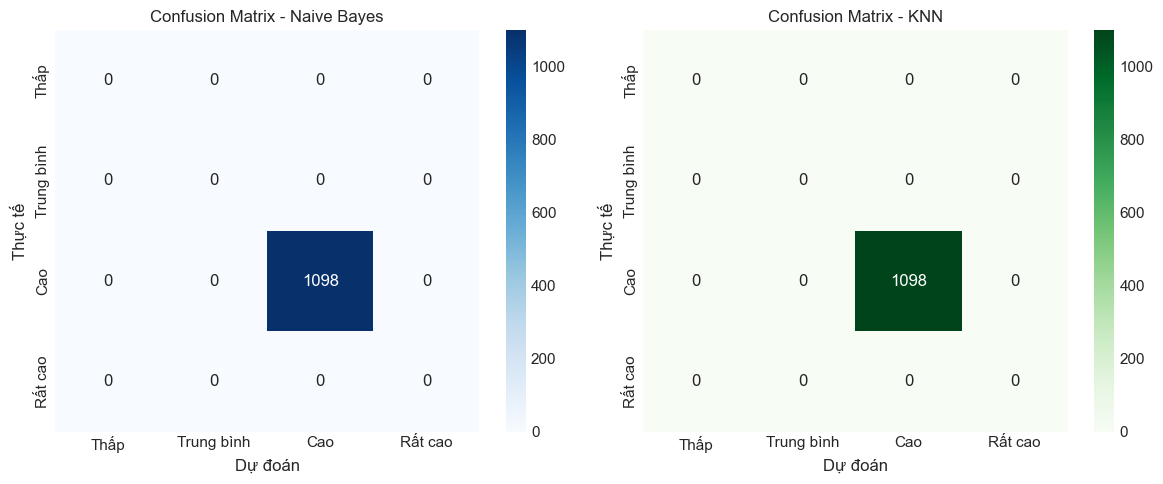

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
# Đọc dữ liệu 
df_muc_do = pd.read_csv('df_muc_do.csv')
cols = ['Schizophrenia (%)', 'Bipolar disorder (%)', 'Eating disorders (%)',
        'Anxiety disorders (%)', 'Drug use disorders (%)',
        'Depression (%)', 'Alcohol use disorders (%)']
# Đảm bảo dữ liệu các cột
df[cols] = df[cols].apply(pd.to_numeric, errors='coerce').fillna(0)
# Tách tập train/test
X =df_muc_do[cols]
y = df_muc_do['Muc_do_quan_tam']
# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)
print("Naive Bayes Report:\n", classification_report(y_test, nb_preds))

# KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
knn_preds = knn_model.predict(X_test)
print("KNN Report:\n", classification_report(y_test, knn_preds))

# Vẽ biểu đồ
# Tạo confusion matrix(ma trận nhầm lẫn) cho cả hai mô hình
cm_nb = confusion_matrix(y_test, nb_preds, labels=['Thấp', 'Trung bình', 'Cao', 'Rất cao'])
cm_knn = confusion_matrix(y_test, knn_preds, labels=['Thấp', 'Trung bình', 'Cao', 'Rất cao'])
labels_order = ['Thấp', 'Trung bình', 'Cao', 'Rất cao']

plt.figure(figsize=(12, 5))

# Biểu đồ cho Naive Bayes
plt.subplot(1, 2, 1)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")

# Biểu đồ cho KNN
plt.subplot(1, 2, 2)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', xticklabels=labels_order, yticklabels=labels_order)
plt.title("Confusion Matrix - KNN")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")

plt.tight_layout()
plt.savefig("ConfusionMatrix.png", dpi=90)
plt.show()


 Nhận xét kết quả mô hình Naive Bayes:
- Độ chính xác (Accuracy): 1.00 (100%), cho thấy mô hình có khả năng phân loại chính xác trên tập kiểm tra
- Precision, Recall, F1-score lớp "Cao": Precision, Recall, F1-score đều đạt 1.00
  * Không có bất kỳ lỗi phân loại
  * Không xảy ra hiện tượng nhầm giữa các lớp.
- Phân bố lớp (Class Distribution): Lớp "Cao" có 1098 mẫu
- Macro avg và Weighted avg:
  * Macro avg (trung bình không trọng số): 1.00 cho thấy mô hình hoạt động hoàn toàn đồng đều giữa các lớp.
  * Weighted avg (trung bình theo số lượng mẫu):1.00 cho thấy hoạt động hiệu quả tốt trên toàn tập kiểm tra

 Nhận xét kết quả mô hình KNN:
- Độ chính xác (Accuracy): toàn bộ là 1.00 (100%), cho thấy mô hình có khả năng phân loại chính xác trên tập kiểm tra,thể hiện mô hình phân loại cực kỳ chính xác với dữ liệu hiện tại. Điều này chứng minh rằng các đặc trưng bệnh lý được chọn là phù hợp để dự đoán mức độ quan tâm.
- Precision, Recall, F1-score đều đạt 1.00, cho thấy:
  * Mô hình không có bất kỳ lỗi phân loại nào.
  * Không xảy ra hiện tượng nhầm lẫn giữa các lớp.
- Phân bố lớp (Class Distribution): Lớp "Cao" có 1098 mẫu
- Macro avg và Weighted avg đều đạt 1.00:
  * Macro avg (trung bình không trọng số) cho thấy mô hình hoạt động tốt đồng đều giữa các lớp.
  * Weighted avg (trung bình theo số lượng mẫu) cho thấy hiệu quả tổng thể trên toàn tập kiểm tra là rất ổn định và đáng tin cậy.

##### --> Mô hình KNN cho kết quả giống hoàn toàn với Naive Bayes

 ###  DecisionTree và RandomForest

|--- Anxiety disorders (%) <= 4.81
|   |--- Schizophrenia (%) <= 0.19
|   |   |--- Anxiety disorders (%) <= 3.16
|   |   |   |--- value: [3.43]
|   |   |--- Anxiety disorders (%) >  3.16
|   |   |   |--- value: [3.89]
|   |--- Schizophrenia (%) >  0.19
|   |   |--- Bipolar disorder (%) <= 0.99
|   |   |   |--- value: [3.09]
|   |   |--- Bipolar disorder (%) >  0.99
|   |   |   |--- value: [4.69]
|--- Anxiety disorders (%) >  4.81
|   |--- Bipolar disorder (%) <= 0.62
|   |   |--- Schizophrenia (%) <= 0.32
|   |   |   |--- value: [6.51]
|   |   |--- Schizophrenia (%) >  0.32
|   |   |   |--- value: [6.31]
|   |--- Bipolar disorder (%) >  0.62
|   |   |--- Drug use disorders (%) <= 0.97
|   |   |   |--- value: [3.73]
|   |   |--- Drug use disorders (%) >  0.97
|   |   |   |--- value: [4.11]



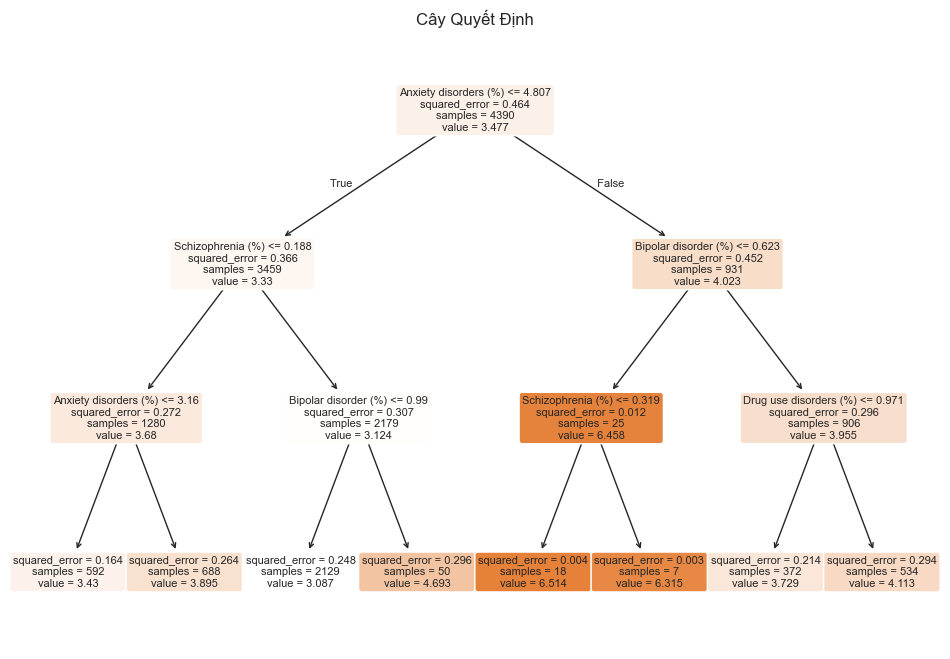

In [84]:
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor, export_text 
from sklearn.model_selection import train_test_split 
from sklearn.metrics import mean_squared_error 
from sklearn.impute import SimpleImputer

# Loại bỏ các dòng thiếu biến mục tiêu 'Trầm cảm (%)' để dễ dàng xử lý thông tin.
df.dropna(subset=['Depression (%)'], inplace=True)

# Chọn các cột liên quan cho các đặc điểm (X) và mục tiêu (y)
X = df[['Year', 'Schizophrenia (%)', 'Bipolar disorder (%)', 'Eating disorders (%)', 'Anxiety disorders (%)', 'Drug use disorders (%)']]
y = df['Depression (%)']

# Chia dữ liệu thành các tập huấn luyện và kiểm tra cho thiết kế cây.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Điền vào các giá trị thiếu bằng trung bình của mỗi cột, tạo ra các giá trị cần thiết và bỏ qua những gì không cần thiết.
imputer = SimpleImputer(strategy='mean')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Xây dựng mô hình cây quyết định
tree = DecisionTreeRegressor(max_depth=3)
tree.fit(X_train_imputed, y_train)

# Đánh giá mô hình
y_pred = tree.predict(X_test_imputed)
mse = mean_squared_error(y_test, y_pred)

# Tạo một đại diện văn bản của cây quyết định
tree_rules = export_text(tree, feature_names=X.columns.tolist())

# In ấn các quy tắc của cây quyết định
print(tree_rules)

# Vẽ biểu đồ cây quyết định
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True, fontsize=8)
plt.title('Cây Quyết Định')
plt.savefig("cay_quyet_dinh.png", dpi=90)
plt.show()

* Gốc: Anxiety disorders (%) ≤ 4.807. 
* Nhánh trái (True): Tiếp tục chia dựa trên Schizophrenia (%) ≤ 0.188.
Nếu thấp hơn mức này, mô hình xem xét tiếp Anxiety disorders (%) hoặc Bipolar disorder (%). Giá trị dự đoán dao động từ khoảng 3.087 đến 4.693.
* Nhánh phải (False): Chia dựa trên Bipolar disorder (%) ≤ 0.623. Nếu nhỏ hơn, tiếp tục dựa vào Schizophrenia (%); nếu lớn hơn, dựa vào Drug use disorders (%). Một số nút có giá trị dự đoán cao hơn hẳn (6.315, 6.514) cho thấy các mẫu trong nhóm này có tỷ lệ mục tiêu rất cao.

* Ý nghĩa:
- Các biến Anxiety disorders (%), Schizophrenia (%), và Bipolar disorder (%) là các yếu tố quan trọng hàng đầu trong việc phân loại/dự đoán.
- Một số nhóm nhỏ có giá trị dự đoán cao bất thường, cần xem xét vì có thể ảnh hưởng bởi ngoại lệ hoặc số liệu cực trị.

##### Dự đoán tỷ lệ trầm cảm (Depression (%)) bằng cách sử dụng 2 mô hình học máy: DecisionTreeRegressor và RandomForestRegressor. 

C:\Users\Admin\AppData\Local\Temp\ipykernel_17320\3921217896.py:10: DtypeWarning: Columns (5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('health.csv')


ĐÁNH GIÁ MÔ HÌNH
Decision Tree - MSE: 0.01, R²: 0.97
Random Forest  - MSE: 0.00, R²: 0.99


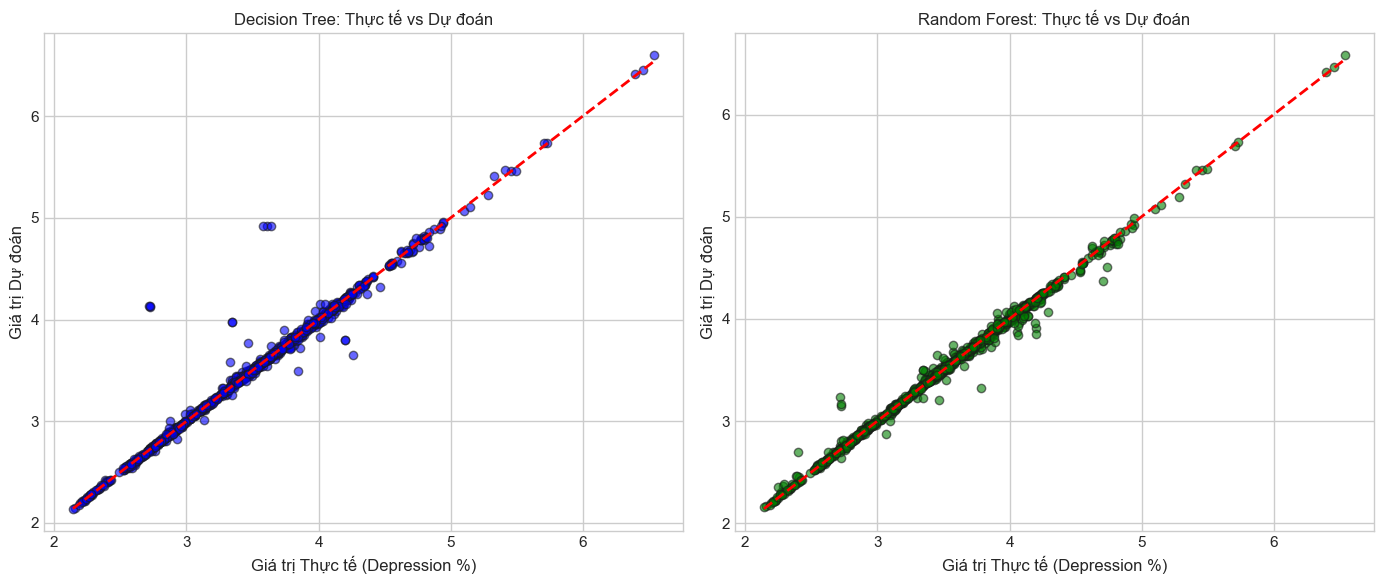

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Đọc dữ liệu
df = pd.read_csv('health.csv')

# Loại bỏ giá trị thiếu (nếu có)
df = df.dropna()

# Mã hóa các cột phân loại ('Entity', 'Code')
label_encoder_entity = LabelEncoder()
label_encoder_code = LabelEncoder()

df['Entity'] = label_encoder_entity.fit_transform(df['Entity'].astype(str))
df['Code'] = label_encoder_code.fit_transform(df['Code'].astype(str))

# Chọn đặc trưng đầu vào X và biến mục tiêu y
X = df.drop('Depression (%)', axis=1)
y = df['Depression (%)']

# Chia dữ liệu thành train và test (80% - 20%). Lấy 20% dữ liệu để kiểm tra (test set) và 80% dữ liệu để huấn luyện (train set).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Mô hình Decision Tree
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# Mô hình Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("ĐÁNH GIÁ MÔ HÌNH")
print(f"Decision Tree - MSE: {mean_squared_error(y_test, y_pred_dt):.2f}, R²: {r2_score(y_test, y_pred_dt):.2f}")
print(f"Random Forest  - MSE: {mean_squared_error(y_test, y_pred_rf):.2f}, R²: {r2_score(y_test, y_pred_rf):.2f}")
# Trực quan hóa kết quả
plt.figure(figsize=(14, 6))
#Biểu đồ cho Decision Tree
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_dt, color='blue', edgecolor='k', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2)
plt.title('Decision Tree: Thực tế vs Dự đoán')
plt.xlabel('Giá trị Thực tế (Depression %)')
plt.ylabel('Giá trị Dự đoán')
plt.grid(True)
# Biểu đồ cho Random Forest
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_rf, color='green', edgecolor='k', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2)
plt.title('Random Forest: Thực tế vs Dự đoán')
plt.xlabel('Giá trị Thực tế (Depression %)')
plt.ylabel('Giá trị Dự đoán')
plt.grid(True)
plt.tight_layout()
plt.savefig("MSE.png", dpi=90)
plt.show()


- Decision Tree - MSE: 0.01, R²: 0.97, Mô hình khá chính xác. Các điểm đa số nằm dọc theo đường chéo, nhưng vẫn có một số điểm lệch xa, thể hiện sự hơi thiếu ổn định
- Random Forest  - MSE: 0.00, R²: 0.99, Mô hình cực kỳ chính xác, gần như khớp với dữ liệu thực. Các điểm bám sát đường chéo, gần như không có nhiễu
- (MSE càng thấp thì mô hình dự đoán càng gần giá trị thực.
R² gần 1 → mô hình giải thích rất tốt phương sai của dữ liệu đầu vào)
##### --> Random Forest vượt trội với độ chính xác cao hơn và sai số nhỏ hơn đáng kể.